In [5]:
import pandas as pd

df = pd.read_csv("D:\\Workspace\\data\\WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nAttrition counts:")
print(df["Attrition"].value_counts(dropna=False))


Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types:
Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
Environm

In [9]:
# Total employees and attrition counts
total_employees = len(df)
attrition_counts = df["Attrition"].value_counts()

# Calculate attrition rate
employees_left = (df["Attrition"] == "Yes").sum()
attrition_rate = employees_left / total_employees * 100

print(f"Total employees: {total_employees}")
print(f"Employees who left: {employees_left}")
print(f"Employees who stayed: {(df['Attrition'] == 'No').sum()}")
print(f"Attrition rate: {attrition_rate:.2f}%")

print("\nAttrition breakdown:")
print(attrition_counts)

Total employees: 1470
Employees who left: 237
Employees who stayed: 1233
Attrition rate: 16.12%

Attrition breakdown:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [11]:
department_analysis = (
    df.groupby("Department")
      .agg(
          employees=("Attrition", "size"),
          employees_left=("Attrition",
                          lambda x: (x == "Yes").sum())
      )
)

department_analysis["attrition_rate_pct"] = (
    department_analysis["employees_left"]
    / department_analysis["employees"] * 100
)

department_analysis = department_analysis.sort_values(
    "attrition_rate_pct", ascending=False
)

print(department_analysis.round(2))

                        employees  employees_left  attrition_rate_pct
Department                                                           
Sales                         446              92               20.63
Human Resources                63              12               19.05
Research & Development        961             133               13.84


In [13]:
overtime_analysis = (
    df.groupby("OverTime")
      .agg(
          employees=("Attrition", "size"),
          employees_left=("Attrition",
                          lambda x: (x == "Yes").sum())
      )
)

overtime_analysis["attrition_rate_pct"] = (
    overtime_analysis["employees_left"]
    / overtime_analysis["employees"] * 100
)

print(overtime_analysis.round(2))

          employees  employees_left  attrition_rate_pct
OverTime                                               
No             1054             110               10.44
Yes             416             127               30.53


In [17]:
overtime_analysis = (
    df.groupby("YearsAtCompany")
      .agg(
          employees=("Attrition", "size"),
          employees_left=("Attrition",
                          lambda x: (x == "Yes").sum())
      )
)

overtime_analysis["attrition_rate_pct"] = (
    overtime_analysis["employees_left"]
    / overtime_analysis["employees"] * 100
)

print(overtime_analysis.round(2))

                employees  employees_left  attrition_rate_pct
YearsAtCompany                                               
0                      44              16               36.36
1                     171              59               34.50
2                     127              27               21.26
3                     128              20               15.62
4                     110              19               17.27
5                     196              21               10.71
6                      76               9               11.84
7                      90              11               12.22
8                      80               9               11.25
9                      82               8                9.76
10                    120              18               15.00
11                     32               2                6.25
12                     14               0                0.00
13                     24               2                8.33
14      

In [19]:
role_analysis = (
    df.groupby("JobRole")
      .agg(
          employees=("Attrition", "size"),
          employees_left=("Attrition",
                          lambda x: (x == "Yes").sum())
      )
)

role_analysis["attrition_rate_pct"] = (
    role_analysis["employees_left"]
    / role_analysis["employees"] * 100
)

role_analysis = role_analysis.sort_values(
    "attrition_rate_pct", ascending=False
)

print(role_analysis.round(2))

                           employees  employees_left  attrition_rate_pct
JobRole                                                                 
Sales Representative              83              33               39.76
Laboratory Technician            259              62               23.94
Human Resources                   52              12               23.08
Sales Executive                  326              57               17.48
Research Scientist               292              47               16.10
Manufacturing Director           145              10                6.90
Healthcare Representative        131               9                6.87
Manager                          102               5                4.90
Research Director                 80               2                2.50


In [21]:
early_tenure = df[df["YearsAtCompany"] <= 1]

early_overtime = (
    early_tenure.groupby("OverTime")
      .agg(
          employees=("Attrition", "size"),
          employees_left=(
              "Attrition",
              lambda x: (x == "Yes").sum()
          )
      )
)

early_overtime["attrition_rate_pct"] = (
    early_overtime["employees_left"]
    / early_overtime["employees"] * 100
)

print(early_overtime.round(2))

          employees  employees_left  attrition_rate_pct
OverTime                                               
No              146              37               25.34
Yes              69              38               55.07


In [23]:
# 1. Attrition by job role and overtime
role_overtime = (
    df.groupby(["JobRole", "OverTime"], observed=True)
      .agg(
          employees=("Attrition", "size"),
          employees_left=(
              "Attrition",
              lambda x: (x == "Yes").sum()
          )
      )
      .reset_index()
)

role_overtime["attrition_rate_pct"] = (
    role_overtime["employees_left"]
    / role_overtime["employees"] * 100
)

print("ATTRITION BY JOB ROLE AND OVERTIME")
print(role_overtime.round(2).to_string(index=False))


# 2. Attrition by job role for employees with 0–1 years
early = df[df["YearsAtCompany"] <= 1]

early_role = (
    early.groupby("JobRole", observed=True)
         .agg(
             employees=("Attrition", "size"),
             employees_left=(
                 "Attrition",
                 lambda x: (x == "Yes").sum()
             )
         )
)

early_role["attrition_rate_pct"] = (
    early_role["employees_left"]
    / early_role["employees"] * 100
)

print("\nEARLY-TENURE ATTRITION BY JOB ROLE")
print(early_role.sort_values(
    "attrition_rate_pct", ascending=False
).round(2))

ATTRITION BY JOB ROLE AND OVERTIME
                  JobRole OverTime  employees  employees_left  attrition_rate_pct
Healthcare Representative       No         94               7                7.45
Healthcare Representative      Yes         37               2                5.41
          Human Resources       No         39               7               17.95
          Human Resources      Yes         13               5               38.46
    Laboratory Technician       No        197              31               15.74
    Laboratory Technician      Yes         62              31               50.00
                  Manager       No         75               1                1.33
                  Manager      Yes         27               4               14.81
   Manufacturing Director       No        106               6                5.66
   Manufacturing Director      Yes         39               4               10.26
        Research Director       No         57               1  

In [ ]:
ATTRITION BY JOB ROLE AND OVERTIME
                  JobRole OverTime  employees  employees_left  attrition_rate_pct
Healthcare Representative       No         94               7                7.45
Healthcare Representative      Yes         37               2                5.41
          Human Resources       No         39               7               17.95
          Human Resources      Yes         13               5               38.46
    Laboratory Technician       No        197              31               15.74
    Laboratory Technician      Yes         62              31               50.00
                  Manager       No         75               1                1.33
                  Manager      Yes         27               4               14.81
   Manufacturing Director       No        106               6                5.66
   Manufacturing Director      Yes         39               4               10.26
        Research Director       No         57               1                1.75
        Research Director      Yes         23               1                4.35
       Research Scientist       No        195              14                7.18
       Research Scientist      Yes         97              33               34.02
          Sales Executive       No        232              26               11.21
          Sales Executive      Yes         94              31               32.98
     Sales Representative       No         59              17               28.81
     Sales Representative      Yes         24              16               66.67

EARLY-TENURE ATTRITION BY JOB ROLE
                           employees  employees_left  attrition_rate_pct
JobRole                                                                 
Human Resources                    5               4               80.00
Sales Representative              30              17               56.67
Laboratory Technician             61              28               45.90
Sales Executive                   25               7               28.00
Research Scientist                54              14               25.93
Healthcare Representative         13               3               23.08
Manufacturing Director            12               2               16.67
Manager                            9               0                0.00
Research Director                  6               0                0.00

In [25]:
experience_columns = [
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance"
]

for col in experience_columns:
    print(f"\n--- {col} ---")

    summary = (
        df.groupby([col, "Attrition"], observed=True)
          .size()
          .unstack(fill_value=0)
    )

    summary["total_employees"] = summary.sum(axis=1)

    summary["attrition_rate_pct"] = (
        summary.get("Yes", 0)
        / summary["total_employees"] * 100
    )

    print(summary.round(2))


--- JobSatisfaction ---
Attrition         No  Yes  total_employees  attrition_rate_pct
JobSatisfaction                                               
1                223   66              289               22.84
2                234   46              280               16.43
3                369   73              442               16.52
4                407   52              459               11.33

--- EnvironmentSatisfaction ---
Attrition                 No  Yes  total_employees  attrition_rate_pct
EnvironmentSatisfaction                                               
1                        212   72              284               25.35
2                        244   43              287               14.98
3                        391   62              453               13.69
4                        386   60              446               13.45

--- WorkLifeBalance ---
Attrition         No  Yes  total_employees  attrition_rate_pct
WorkLifeBalance                                   

In [27]:
import sqlite3

# Create a local SQLite database file
conn = sqlite3.connect("attrition_analysis.db")

# Load the DataFrame into a SQL table
df.to_sql(
    "employees",
    conn,
    if_exists="replace",
    index=False
)

print("Data loaded into SQLite successfully.")

Data loaded into SQLite successfully.


In [29]:
query = """
SELECT COUNT(*) AS total_employees
FROM employees;
"""

pd.read_sql_query(query, conn)

,total_employees
0,1470


In [31]:
query = """
SELECT
    COUNT(*) AS total_employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_left,
    ROUND(
        100.0 * SUM(
            CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS attrition_rate_pct
FROM employees;
"""

pd.read_sql_query(query, conn)

,total_employees,employees_left,attrition_rate_pct
0,1470,237,16.12


In [33]:
query = """
SELECT
    JobRole,
    COUNT(*) AS employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_left,
    ROUND(
        100.0 * SUM(
            CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS attrition_rate_pct
FROM employees
GROUP BY JobRole
ORDER BY attrition_rate_pct DESC;
"""

pd.read_sql_query(query, conn)

,JobRole,employees,employees_left,attrition_rate_pct
0,Sales Representative,83,33,39.76
1,Laboratory Technician,259,62,23.94
2,Human Resources,52,12,23.08
3,Sales Executive,326,57,17.48
4,Research Scientist,292,47,16.10
5,Manufacturing Director,145,10,6.90
6,Healthcare Representative,131,9,6.87
7,Manager,102,5,4.90
8,Research Director,80,2,2.50


In [35]:
query = """
SELECT
    OverTime,
    COUNT(*) AS employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_left,
    ROUND(
        100.0 * SUM(
            CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS attrition_rate_pct
FROM employees
GROUP BY OverTime
ORDER BY attrition_rate_pct DESC;
"""

pd.read_sql_query(query, conn)

,OverTime,employees,employees_left,attrition_rate_pct
0,Yes,416,127,30.53
1,No,1054,110,10.44


In [41]:


SELECT
    COUNT(*) AS total_employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_left,
    ROUND(
        100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS attrition_rate_pct
FROM employees;

-- 2. Attrition by job role
SELECT
    JobRole,
    COUNT(*) AS employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_left,
    ROUND(
        100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS attrition_rate_pct
FROM employees
GROUP BY JobRole
ORDER BY attrition_rate_pct DESC;

-- 3. Attrition by overtime
SELECT
    OverTime,
    COUNT(*) AS employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_left,
    ROUND(
        100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS attrition_rate_pct
FROM employees
GROUP BY OverTime
ORDER BY attrition_rate_pct DESC;


IndentationError: unexpected indent (3656836767.py, line 2)

In [43]:
from pathlib import Path

output_dir = Path("report_data")
output_dir.mkdir(exist_ok=True)

# Overall attrition
overall = pd.DataFrame({
    "metric": [
        "Total employees",
        "Employees who left",
        "Attrition rate (%)"
    ],
    "value": [
        len(df),
        (df["Attrition"] == "Yes").sum(),
        round((df["Attrition"] == "Yes").mean() * 100, 2)
    ]
})

overall.to_csv(output_dir / "overall_attrition.csv", index=False)

# Attrition by job role
role_analysis.to_csv(output_dir / "attrition_by_job_role.csv")

# Attrition by overtime
overtime_analysis.to_csv(output_dir / "attrition_by_overtime.csv")

print("Report tables saved to:", output_dir.resolve())

Report tables saved to: C:\Users\hp\report_data


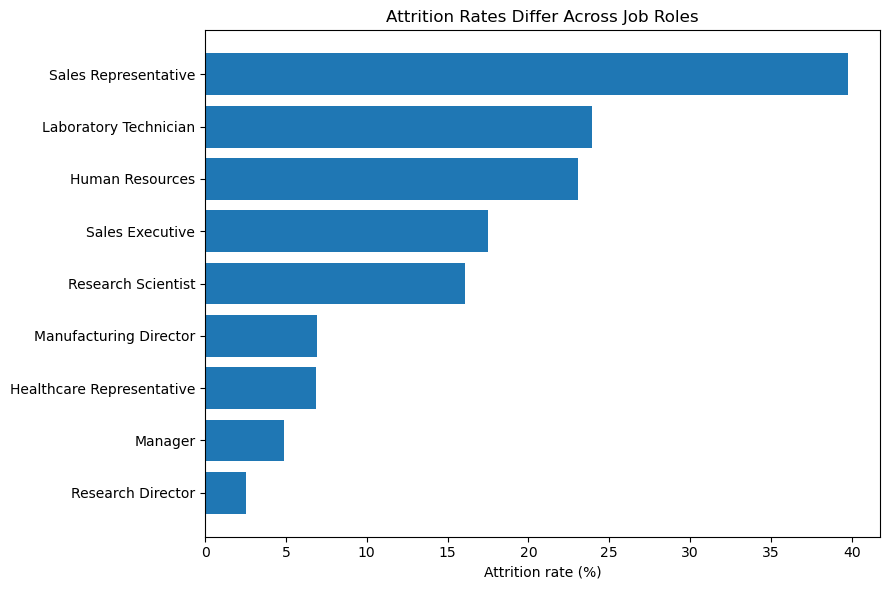

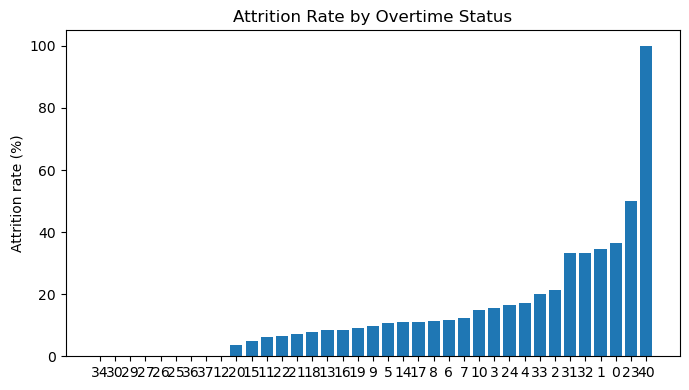

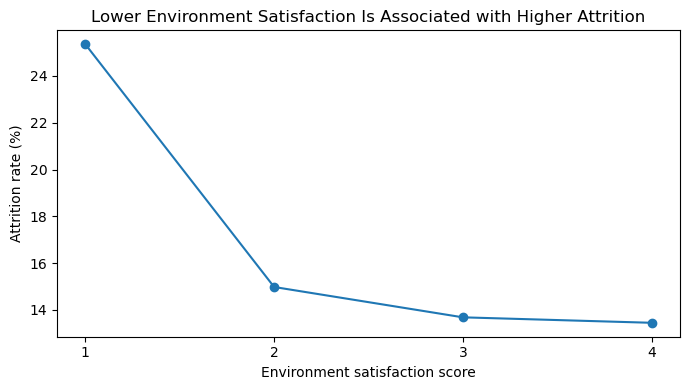

In [45]:
import matplotlib.pyplot as plt

# Chart 1: Attrition by job role
role_plot = role_analysis.sort_values("attrition_rate_pct")

plt.figure(figsize=(9, 6))
plt.barh(
    role_plot.index,
    role_plot["attrition_rate_pct"]
)
plt.xlabel("Attrition rate (%)")
plt.title("Attrition Rates Differ Across Job Roles")
plt.tight_layout()
plt.savefig("attrition_by_job_role.png", dpi=200, bbox_inches="tight")
plt.show()


# Chart 2: Attrition by overtime
overtime_plot = overtime_analysis.sort_values("attrition_rate_pct")

plt.figure(figsize=(7, 4))
plt.bar(
    overtime_plot.index.astype(str),
    overtime_plot["attrition_rate_pct"]
)
plt.ylabel("Attrition rate (%)")
plt.title("Attrition Rate by Overtime Status")
plt.tight_layout()
plt.savefig("attrition_by_overtime.png", dpi=200, bbox_inches="tight")
plt.show()


# Chart 3: Attrition by environment satisfaction
environment_summary = (
    df.groupby("EnvironmentSatisfaction", observed=True)
      .agg(
          employees=("Attrition", "size"),
          employees_left=(
              "Attrition",
              lambda x: (x == "Yes").sum()
          )
      )
)

environment_summary["attrition_rate_pct"] = (
    environment_summary["employees_left"]
    / environment_summary["employees"] * 100
)

plt.figure(figsize=(7, 4))
plt.plot(
    environment_summary.index,
    environment_summary["attrition_rate_pct"],
    marker="o"
)
plt.xticks([1, 2, 3, 4])
plt.xlabel("Environment satisfaction score")
plt.ylabel("Attrition rate (%)")
plt.title("Lower Environment Satisfaction Is Associated with Higher Attrition")
plt.tight_layout()
plt.savefig("attrition_by_environment_satisfaction.png", dpi=200, bbox_inches="tight")
plt.show()